# BETH Veri Seti ile Anomali Tespiti (Kernel-Level Süreç Olayları) — CRISP-DM

**Problem:** Bir honeypot sunucusunda kaydedilen **kernel seviyesindeki süreç olaylarından** (system call) gerçek saldırı aktivitesini,
**etiketsiz (unsupervised)** yöntemlerle, yani yalnızca normal davranışı öğrenerek tespit etmek — *Out-of-Distribution (OoD)* analizi.

**Veri seti:** [BETH Dataset](https://www.semanticscholar.org/paper/BETH-Dataset:-Real-Cybersecurity-Data-for-Anomaly-Highnam-Arulkumaran/87ad3e19552aec6679636e7a309644d2f053c2cb)
(Highnam vd., 2021) — 8 milyondan fazla gerçek olay. Etiketler: `sus` (şüpheli) ve `evil` (saldırgan aktivitesi).
Bu repoda resmi train / validation / test ayrımlarından sabit tohumlu **40.000 / 12.000 / 12.000** satırlık örnekler kullanılır.

**Yöntem:** Makaledeki özellik mühendisliği → 5 farklı anomali algoritması (Isolation Forest, Local Outlier Factor, One-Class SVM,
Autoencoder, PCA yeniden yapılandırma hatası) → **AutoML**: Genetik Algoritma ile algoritma + hiperparametre seçimi
(yalnızca **validation** verisiyle; test seti hiç kullanılmadan).

## 1. İş Anlayışı (Business Understanding)
- İmza tabanlı sistemler bilinmeyen (zero-day) saldırıları kaçırır. Normal sistem davranışını öğrenip bundan sapmaları işaretleyen bir model, yeni saldırıları da yakalayabilir.
- **Kritik koşul:** Eğitim ve validation verisinde saldırı (evil) yoktur; model saldırı görmeden eğitilir. Test verisi ise saldırı içerir → gerçek bir OoD senaryosu.
- **Başarı ölçütleri:** Eşikten bağımsız **ROC-AUC** ve **PR-AUC (Average Precision)**; operasyonel eşikte precision / recall / F1.

In [1]:
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (average_precision_score, classification_report, precision_recall_curve,
                             roc_auc_score, roc_curve)
from sklearn.neighbors import LocalOutlierFactor
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.svm import OneClassSVM

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
SEED = 42
DATA = Path("../data")
FIG = Path("../docs/figures"); FIG.mkdir(parents=True, exist_ok=True)
MODELS = Path("../models"); MODELS.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid")

## 2. Veri Anlayışı (Data Understanding)

In [2]:
train = pd.read_csv(DATA / "beth_training_sample.csv")
val = pd.read_csv(DATA / "beth_validation_sample.csv")
test = pd.read_csv(DATA / "beth_testing_sample.csv")
for n, d in [("train", train), ("validation", val), ("test", test)]:
    print(f"{n:10s} {d.shape}  sus oranı={d['sus'].mean():.3f}  evil oranı={d['evil'].mean():.3f}")
train.head(3)

train      (40000, 16)  sus oranı=0.002  evil oranı=0.000
validation (12000, 16)  sus oranı=0.003  evil oranı=0.000
test       (12000, 16)  sus oranı=0.904  evil oranı=0.837


,timestamp,processId,threadId,parentProcessId,userId,mountNamespace,processName,hostName,eventId,eventName,stackAddresses,argsNum,returnValue,args,sus,evil
0,406.255551,7303,7303,187,0,4026532217,systemd-udevd,ubuntu,257,openat,[],4,6,"[{'name': 'dirfd', 'type': 'int', 'value': -10...",0,0
1,1556.444427,159,159,1,0,4026531840,systemd-journal,ip-10-100-1-57,1005,security_file_open,"[140096430554916, 3418923110323139120]",4,0,"[{'name': 'pathname', 'type': 'const char*', '...",0,0
2,1704.112616,7365,7365,1649,0,4026531840,ps,ip-10-100-1-28,257,openat,[],4,9,"[{'name': 'dirfd', 'type': 'int', 'value': -10...",0,0


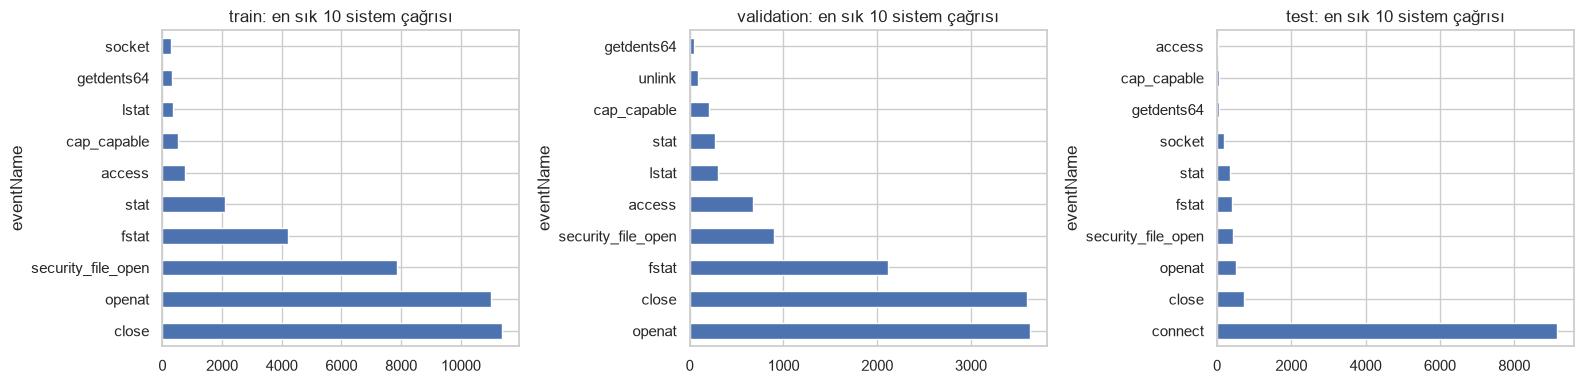

Test'te evil olayların en sık süreç adları:
 processName
tsm       9431
sshd        69
w           62
passwd      53
grep        52
sh          45
rm          30
bash        26


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (n, d) in zip(axes, [("train", train), ("validation", val), ("test", test)]):
    d["eventName"].value_counts().head(10).plot.barh(ax=ax); ax.set_title(f"{n}: en sık 10 sistem çağrısı")
plt.tight_layout(); plt.savefig(FIG / "event_distribution.png", dpi=120); plt.show()
print("Test'te evil olayların en sık süreç adları:\n", test.loc[test.evil == 1, "processName"].value_counts().head(8).to_string())

**Gözlemler**
- Train ve validation neredeyse tamamen normal; test setinin büyük bölümü saldırgan aktivitesidir (veri setinin orijinal yapısı).
- Sistem çağrısı dağılımı ve süreç isimleri train ile test arasında belirgin şekilde değişiyor → bu **dağılım kayması** OoD tespitinin temelidir.
- `args`, `stackAddresses`, `hostName` gibi alanlar yüksek kardinaliteli ve ortama özeldir; makaledeki öneriye uygun olarak doğrudan kullanılmaz.

## 3. Veri Hazırlama (Data Preparation)
BETH makalesinde önerilen özellikler:
| Özellik | Dönüşüm | Anlamı |
|---|---|---|
| processId, parentProcessId | {0,1,2} ise 1 | İşletim sistemi (init/kthreadd) süreci mi |
| userId | < 1000 ise 1 | Sistem kullanıcısı mı |
| mountNamespace | 4026531840 ise 1 | Ana (host) namespace'te mi |
| eventId | olduğu gibi | Sistem çağrısı türü |
| argsNum | olduğu gibi | Argüman sayısı |
| returnValue | işaret: -1 / 0 / 1 | Hata / başarı / pozitif dönüş |

In [4]:
def features(d: pd.DataFrame) -> pd.DataFrame:
    return pd.DataFrame({
        "processId": d["processId"].isin([0, 1, 2]).astype(int),
        "parentProcessId": d["parentProcessId"].isin([0, 1, 2]).astype(int),
        "userId": (d["userId"] < 1000).astype(int),
        "mountNamespace": (d["mountNamespace"] == 4026531840).astype(int),
        "eventId": d["eventId"],
        "argsNum": d["argsNum"],
        "returnValue": np.sign(d["returnValue"]).astype(int),
    })


scaler = StandardScaler().fit(features(train))
X_train, X_val, X_test = (scaler.transform(features(d)) for d in (train, val, test))
y_val_sus, y_test = val["sus"].values, test["evil"].values
print("Özellikler:", list(features(train).columns))

Özellikler: ['processId', 'parentProcessId', 'userId', 'mountNamespace', 'eventId', 'argsNum', 'returnValue']


## 4. Modelleme (Modeling)
### 4.1 Beş farklı anomali tespit algoritması
Tüm modeller **yalnızca train** verisiyle eğitilir. Skorlar "yüksek = daha anormal" olacak şekilde yönlendirilir.
One-Class SVM'in O(n²) maliyeti nedeniyle 10.000 satırlık bir alt örnekle eğitilir.

In [5]:
rng = np.random.default_rng(SEED)
sub10k = X_train[rng.choice(len(X_train), 10_000, replace=False)]


class AE:
    """Basit autoencoder: girdiyi darboğazdan geçirip yeniden üretir; skor = yeniden yapılandırma hatası."""
    def __init__(self, hidden=(16, 3, 16), alpha=1e-4, lr=1e-3):
        self.m = MLPRegressor(hidden_layer_sizes=hidden, alpha=alpha, learning_rate_init=lr, max_iter=200, random_state=SEED)
    def fit(self, X):
        self.m.fit(X, X); return self
    def score(self, X):
        return ((self.m.predict(X) - X) ** 2).mean(axis=1)


class PCARecon:
    def __init__(self, n=3):
        self.p = PCA(n_components=n, random_state=SEED)
    def fit(self, X):
        self.p.fit(X); return self
    def score(self, X):
        return ((self.p.inverse_transform(self.p.transform(X)) - X) ** 2).sum(axis=1)


def make(algo, data=None, **kw):
    full = X_train if data is None else data
    small = sub10k if data is None else data
    if algo == "IsolationForest":
        m = IsolationForest(n_estimators=kw.get("n_estimators", 200), max_samples=kw.get("max_samples", 256),
                            max_features=kw.get("max_features", 1.0), random_state=SEED, n_jobs=-1).fit(full)
        return lambda X: -m.score_samples(X)
    if algo == "LOF":
        m = LocalOutlierFactor(n_neighbors=kw.get("n_neighbors", 20), novelty=True, n_jobs=-1).fit(small)
        return lambda X: -m.score_samples(X)
    if algo == "OneClassSVM":
        m = OneClassSVM(nu=kw.get("nu", 0.05), gamma=kw.get("gamma", "scale")).fit(small)
        return lambda X: -m.score_samples(X)
    if algo == "Autoencoder":
        m = AE(hidden=(kw.get("h1", 16), kw.get("bottleneck", 3), kw.get("h1", 16)), alpha=kw.get("alpha", 1e-4), lr=kw.get("lr", 1e-3)).fit(full)
        return m.score
    m = PCARecon(n=kw.get("n", 3)).fit(full)
    return m.score


rows, scorers = [], {}
for algo in ["IsolationForest", "LOF", "OneClassSVM", "Autoencoder", "PCA"]:
    f = make(algo)
    scorers[algo] = f
    sv = f(X_val)
    rows.append({"Model": algo, "Val ROC-AUC (sus)": roc_auc_score(y_val_sus, sv), "Val PR-AUC (sus)": average_precision_score(y_val_sus, sv)})
baseline = pd.DataFrame(rows).sort_values("Val PR-AUC (sus)", ascending=False).reset_index(drop=True)
baseline.round(4)

,Model,Val ROC-AUC (sus),Val PR-AUC (sus)
0,OneClassSVM,1.0000,1.0000
1,PCA,1.0000,1.0000
2,LOF,0.9923,0.6906
3,Autoencoder,0.9689,0.1980
4,IsolationForest,0.9102,0.0219


### 4.2 AutoML — Genetik Algoritma ile algoritma + hiperparametre seçimi
**Çok amaçlı (NSGA-II) optimizasyon.** Validation setinde yalnızca 40 şüpheli (`sus`) olay var ve iyi modellerin çoğunda hem ROC-AUC hem
PR-AUC 1.0'a doyuyor; etiket tabanlı tek bir metrik konfigürasyonları ayırt edemiyor ve aşırı uyuma (proxy etikete overfit) açık hale geliyor.
Bu yüzden genetik algoritma iki amacı birlikte maksimize ediyor:
1. **PR-AUC (sus)** — şüpheli olayları üst sıralara koyabilme (etiketli amaç),
2. **Kararlılık** — aynı konfigürasyon train'in iki *ayrık* 10k'lık alt örneğiyle ayrı ayrı eğitildiğinde validation olaylarına verdiği
   skorların Spearman sıra korelasyonu (etiketsiz amaç). Veri değişince sıralaması bozulan model, yeni saldırılarda da güvenilmez olur.

Seçim kuralı: PR-AUC'si en iyinin %1'i içinde kalan konfigürasyonlar arasından **en kararlı** olan. Test setindeki `evil` etiketi
optimizasyonda **hiç kullanılmaz**.

In [6]:
from scipy.stats import spearmanr

perm = rng.permutation(len(X_train))
part_a, part_b = X_train[perm[:10_000]], X_train[perm[10_000:20_000]]
val_idx = rng.choice(len(X_val), 3000, replace=False)


def objective(trial):
    algo = trial.suggest_categorical("algorithm", ["IsolationForest", "LOF", "OneClassSVM", "Autoencoder"])
    if algo == "IsolationForest":
        kw = dict(n_estimators=trial.suggest_int("n_estimators", 100, 500, step=50),
                  max_samples=trial.suggest_int("max_samples", 64, 4096, log=True),
                  max_features=trial.suggest_float("max_features", 0.5, 1.0))
    elif algo == "LOF":
        kw = dict(n_neighbors=trial.suggest_int("n_neighbors", 5, 200, log=True))
    elif algo == "OneClassSVM":
        kw = dict(nu=trial.suggest_float("nu", 0.005, 0.3, log=True), gamma=trial.suggest_float("gamma", 1e-3, 2.0, log=True))
    else:
        kw = dict(h1=trial.suggest_int("h1", 8, 64), bottleneck=trial.suggest_int("bottleneck", 2, 5),
                  alpha=trial.suggest_float("alpha", 1e-6, 1e-2, log=True), lr=trial.suggest_float("lr", 1e-4, 1e-2, log=True))
    ap = average_precision_score(y_val_sus, make(algo, **kw)(X_val))
    xv = X_val[val_idx]
    stab = spearmanr(make(algo, data=part_a, **kw)(xv), make(algo, data=part_b, **kw)(xv)).statistic
    return ap, float(np.nan_to_num(stab))


study = optuna.create_study(directions=["maximize", "maximize"],
                            sampler=optuna.samplers.NSGAIISampler(population_size=10, seed=SEED))
study.optimize(objective, n_trials=40)
top_ap = max(t.values[0] for t in study.trials)
best = max((t for t in study.trials if t.values[0] >= 0.99 * top_ap), key=lambda t: t.values[1])
print(f"Pareto cephesi: {len(study.best_trials)} konfigürasyon")
print(f"Seçilen: PR-AUC={best.values[0]:.4f} | kararlılık={best.values[1]:.3f} | {best.params}")

Pareto cephesi: 4 konfigürasyon
Seçilen: PR-AUC=1.0000 | kararlılık=0.999 | {'algorithm': 'OneClassSVM', 'nu': 0.07534159891754702, 'gamma': 0.010689751565977946}


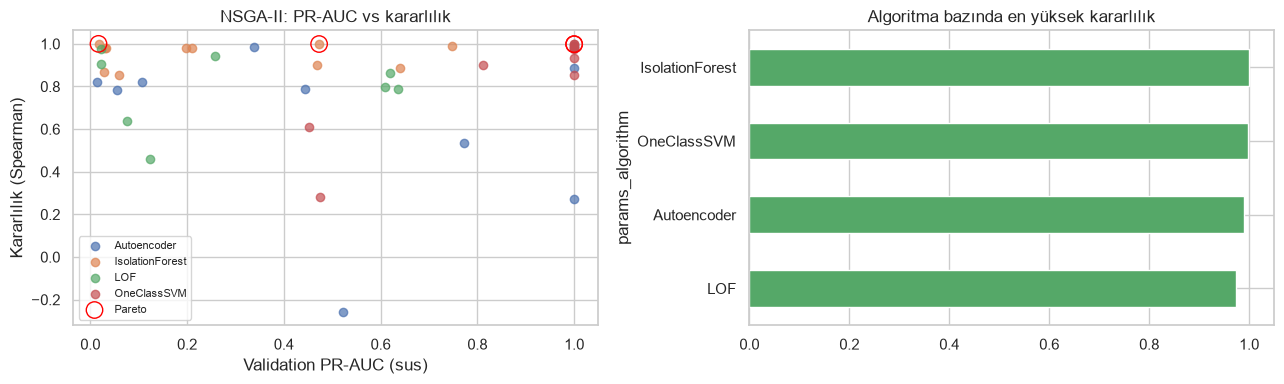

In [7]:
hist = study.trials_dataframe()[["number", "values_0", "values_1", "params_algorithm"]]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for algo, g in hist.groupby("params_algorithm"):
    axes[0].scatter(g["values_0"], g["values_1"], label=algo, alpha=.7)
pf = [t.number for t in study.best_trials]
axes[0].scatter(hist.loc[pf, "values_0"], hist.loc[pf, "values_1"], s=140, facecolors="none", edgecolors="red", label="Pareto")
axes[0].set(title="NSGA-II: PR-AUC vs kararlılık", xlabel="Validation PR-AUC (sus)", ylabel="Kararlılık (Spearman)"); axes[0].legend(fontsize=8)
hist.groupby("params_algorithm")["values_1"].max().sort_values().plot.barh(ax=axes[1], color="#55A868")
axes[1].set_title("Algoritma bazında en yüksek kararlılık")
plt.tight_layout(); plt.savefig(FIG / "automl_history.png", dpi=120); plt.show()

## 5. Değerlendirme (Evaluation) — test setinde gerçek saldırılar (`evil`)

In [8]:
bp = dict(best.params); best_algo = bp.pop("algorithm")
scorers[f"AutoML ({best_algo})"] = make(best_algo, **bp)
res = [{"Model": n, "Test ROC-AUC": roc_auc_score(y_test, f(X_test)), "Test PR-AUC": average_precision_score(y_test, f(X_test))}
       for n, f in scorers.items()]
results = pd.DataFrame(res).sort_values("Test ROC-AUC", ascending=False).reset_index(drop=True)
results.round(4)

,Model,Test ROC-AUC,Test PR-AUC
0,AutoML (OneClassSVM),0.9915,0.9977
1,Autoencoder,0.9910,0.9970
2,OneClassSVM,0.9909,0.9972
3,IsolationForest,0.9152,0.9828
4,PCA,0.9074,0.9777
5,LOF,0.8243,0.9516


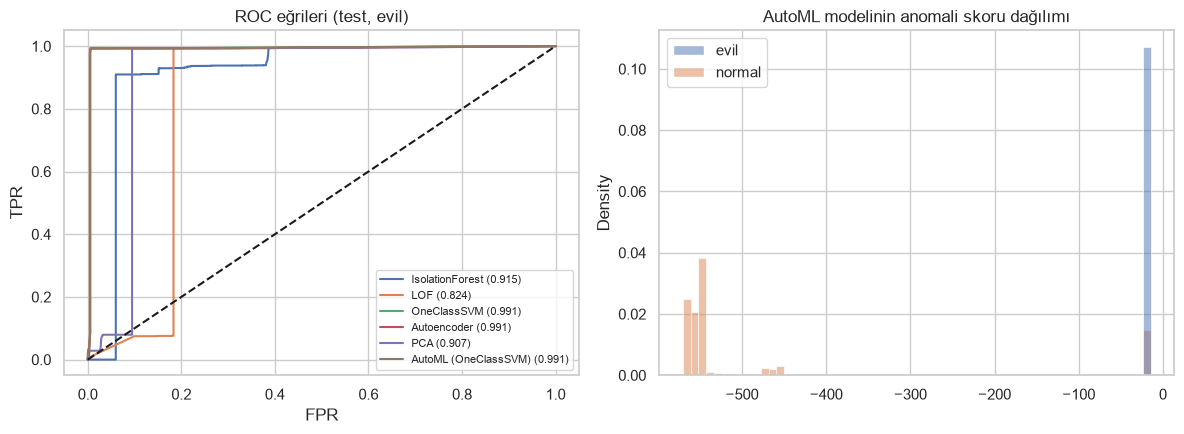

In [9]:
best_scores = scorers[f"AutoML ({best_algo})"](X_test)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for n, f in scorers.items():
    s = f(X_test); fpr, tpr, _ = roc_curve(y_test, s)
    axes[0].plot(fpr, tpr, label=f"{n} ({roc_auc_score(y_test, s):.3f})")
axes[0].plot([0, 1], [0, 1], "k--"); axes[0].set(title="ROC eğrileri (test, evil)", xlabel="FPR", ylabel="TPR"); axes[0].legend(fontsize=8)
sns.histplot(x=best_scores, hue=np.where(y_test == 1, "evil", "normal"), bins=60, stat="density", common_norm=False, ax=axes[1])
axes[1].set_title("AutoML modelinin anomali skoru dağılımı")
plt.tight_layout(); plt.savefig(FIG / "roc_scores.png", dpi=120); plt.show()

**Operasyonel eşik:** Etiketsiz bir senaryoda eşik test etiketine bakılarak seçilemez. Bu yüzden eşik, **validation** setindeki skorların
%99'luk dilimi olarak belirlenir (normal trafiğin yaklaşık %1'i alarm üretir).

In [10]:
val_scores = scorers[f"AutoML ({best_algo})"](X_val)
threshold = np.quantile(val_scores, 0.99)
pred = (best_scores > threshold).astype(int)
print(f"Eşik (validation %99 dilimi): {threshold:.4f}")
print(classification_report(y_test, pred, target_names=["normal", "evil"], digits=4))

Eşik (validation %99 dilimi): -456.9818
              precision    recall  f1-score   support

      normal     0.9597    0.8526    0.9030      1954
        evil     0.9719    0.9930    0.9824     10046

    accuracy                         0.9702     12000
   macro avg     0.9658    0.9228    0.9427     12000
weighted avg     0.9699    0.9702    0.9694     12000



## 6. Dağıtım (Deployment) ve Sonuç

In [11]:
joblib.dump({"scaler": scaler, "algorithm": best_algo, "params": bp, "threshold": float(threshold)}, MODELS / "beth_anomaly_config.joblib")
print("Kaydedildi: models/beth_anomaly_config.joblib")

Kaydedildi: models/beth_anomaly_config.joblib


- **Kullanım:** Model bir EDR/SIEM boru hattında her sistem çağrısı olayını skorlayabilir; eşik üstü olaylar süreç ağacıyla birlikte analiste gönderilir.
- **Bulgular:** Hiç saldırı görmeden eğitilen modeller, test setindeki gerçek saldırgan aktivitesini yüksek ROC-AUC ile ayırt edebildi. Bu, BETH makalesindeki
  "basit, alan bilgisine dayalı özellikler + yoğunluk/izolasyon tabanlı yöntemler güçlü bir başlangıç noktasıdır" bulgusuyla uyumludur.
- **AutoML notu:** Optimizasyon yalnızca validation'daki `sus` etiketiyle yapıldı; test sonucunun iyimser olmaması için bu ayrım önemlidir.
- **Kısıtlar:** Örneklem orijinal verinin küçük bir kısmıdır; test setindeki saldırı oranı gerçek hayattakinden çok yüksektir, bu yüzden PR-AUC ve precision değerleri
  üretimde daha düşük olacaktır. DNS trafiği (veri setinin ikinci parçası) bu çalışmanın kapsamı dışındadır.